In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os
print(os.path.exists('/content/drive/MyDrive/btd/brain_tumor_model.h5'))
print(os.listdir('/content/drive/MyDrive/btd/'))

True
['no', 'yes', 'brain_tumor_model.h5']


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_curve, auc, roc_auc_score)

MODEL_PATH = '/content/drive/MyDrive/btd/brain_tumor_model.h5'
TRAIN_DIR  = '/content/drive/MyDrive/btd/'
PRED_DIR   = '/content/drive/MyDrive/pred3'
IMG_SIZE   = (128, 128)
BATCH_SIZE = 32

print("Model exists:", os.path.exists(MODEL_PATH))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model exists: True


In [ ]:
model = tf.keras.models.load_model(MODEL_PATH)

val_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)
val_data = val_datagen.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='binary', subset='validation', shuffle=False  # MUST be False
)
print("Class indices:", val_data.class_indices)

Found 600 images belonging to 2 classes.
Class indices: {'no': 0, 'yes': 1}


In [ ]:
val_data.reset()
y_prob = model.predict(val_data, verbose=1).ravel()   # shape (N,)
y_true = val_data.classes                              # 0/1 labels
y_pred = (y_prob > 0.5).astype(int)

19/19 ━━━━━━━━━━━━━━━━━━━━ 78s 4s/step


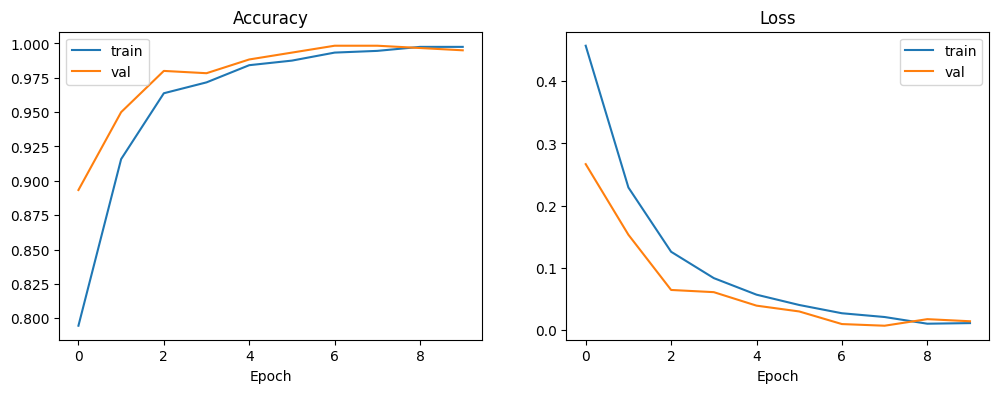

In [ ]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='train'); plt.plot(history.history['val_accuracy'], label='val')
plt.title('Accuracy'); plt.xlabel('Epoch'); plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='train'); plt.plot(history.history['val_loss'], label='val')
plt.title('Loss'); plt.xlabel('Epoch'); plt.legend()
plt.savefig('/content/drive/MyDrive/btd/acc_loss.png', dpi=150, bbox_inches='tight')
plt.show()

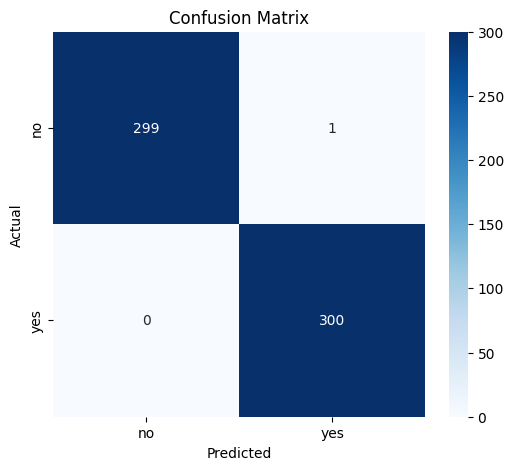

In [ ]:
cm = confusion_matrix(y_true, y_pred)
labels = list(val_data.class_indices.keys())   # e.g. ['non_tumor','tumor']

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.savefig('/content/drive/MyDrive/btd/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
print(classification_report(y_true, y_pred, target_names=labels, digits=4))

              precision    recall  f1-score   support

          no     1.0000    0.9967    0.9983       300
         yes     0.9967    1.0000    0.9983       300

    accuracy                         0.9983       600
   macro avg     0.9983    0.9983    0.9983       600
weighted avg     0.9983    0.9983    0.9983       600



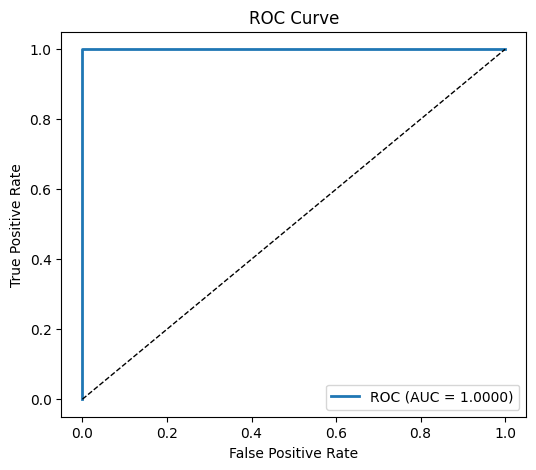

AUC: 1.0


In [ ]:
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, lw=2, label=f'ROC (AUC = {roc_auc:.4f})')
plt.plot([0,1],[0,1],'k--', lw=1)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve'); plt.legend(loc='lower right')
plt.savefig('/content/drive/MyDrive/btd/roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()

print("AUC:", roc_auc)

In [ ]:
def predict_images(folder_path):
    if not os.path.exists(folder_path):
        print("Folder does not exist:", folder_path); return
    for file in os.listdir(folder_path):
        img_path = os.path.join(folder_path, file)
        if not os.path.isfile(img_path): continue
        img = load_img(img_path, target_size=IMG_SIZE)
        arr = np.expand_dims(img_to_array(img) / 255.0, axis=0)
        p = model.predict(arr, verbose=0)[0][0]
        label = "Tumor" if p > 0.5 else "Non-Tumor"
        print(f"{file}: {label}  (prob = {p:.4f})")

predict_images(PRED_DIR)

Tr-me_0246.jpg: Tumor  (prob = 0.9994)
Tr-me_0581.jpg: Tumor  (prob = 0.9999)
Tr-me_0178.jpg: Tumor  (prob = 1.0000)
Tr-me_0595.jpg: Tumor  (prob = 1.0000)
Tr-me_0580.jpg: Tumor  (prob = 1.0000)
Tr-me_0588.jpg: Tumor  (prob = 1.0000)
Tr-me_0187.jpg: Tumor  (prob = 0.9994)
Tr-me_0593.jpg: Tumor  (prob = 1.0000)
Tr-meTr_0008.jpg: Tumor  (prob = 0.9972)
Tr-me_0205.jpg: Tumor  (prob = 1.0000)
Tr-me_0240.jpg: Tumor  (prob = 0.7665)
Tr-meTr_0009.jpg: Non-Tumor  (prob = 0.0035)
Tr-me_0591.jpg: Tumor  (prob = 0.9997)
Tr-me_0217.jpg: Tumor  (prob = 1.0000)
m1(107).jpg: Tumor  (prob = 1.0000)
m (190).jpg: Tumor  (prob = 0.9460)
m1(200).jpg: Tumor  (prob = 1.0000)
Tr-me_1322.jpg: Tumor  (prob = 0.9993)
m1(23).jpg: Tumor  (prob = 0.9186)
m (157).jpg: Non-Tumor  (prob = 0.0143)
Tr-me_1307.jpg: Tumor  (prob = 0.9872)
m3 (138).jpg: Tumor  (prob = 1.0000)
Tr-me_1323.jpg: Tumor  (prob = 1.0000)
m (192).jpg: Non-Tumor  (prob = 0.3936)
Tr-me_1303.jpg: Tumor  (prob = 0.9818)
m (120).jpg: Tumor  (prob = 0.

In [ ]:
import pickle
train_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)
train_data = train_datagen.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='binary', subset='training')

# rebuild same architecture
model2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128,128,3)),
    tf.keras.layers.Conv2D(32,(3,3),activation='relu'),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Conv2D(64,(3,3),activation='relu'),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128,activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1,activation='sigmoid'),
])
model2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history = model2.fit(train_data, validation_data=val_data, epochs=10)

# SAVE history for next time
with open('/content/drive/MyDrive/btd/history.pkl','wb') as f:
    pickle.dump(history.history, f)

Found 2400 images belonging to 2 classes.
Epoch 1/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 95s 1s/step - accuracy: 0.7946 - loss: 0.4569 - val_accuracy: 0.8933 - val_loss: 0.2667
Epoch 2/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 91s 1s/step - accuracy: 0.9158 - loss: 0.2292 - val_accuracy: 0.9500 - val_loss: 0.1533
Epoch 3/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 88s 1s/step - accuracy: 0.9638 - loss: 0.1260 - val_accuracy: 0.9800 - val_loss: 0.0647
Epoch 4/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 90s 1s/step - accuracy: 0.9717 - loss: 0.0837 - val_accuracy: 0.9783 - val_loss: 0.0611
Epoch 5/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 89s 1s/step - accuracy: 0.9842 - loss: 0.0571 - val_accuracy: 0.9883 - val_loss: 0.0395
Epoch 6/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.9875 - loss: 0.0405 - val_accuracy: 0.9933 - val_loss: 0.0301
Epoch 7/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 90s 1s/step - accuracy: 0.9933 - loss: 0.0273 - val_accuracy: 0.9983 - val_loss: 0.0099
Epoch 8/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 92s 1s/step - accuracy: 0.9946 - loss

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━

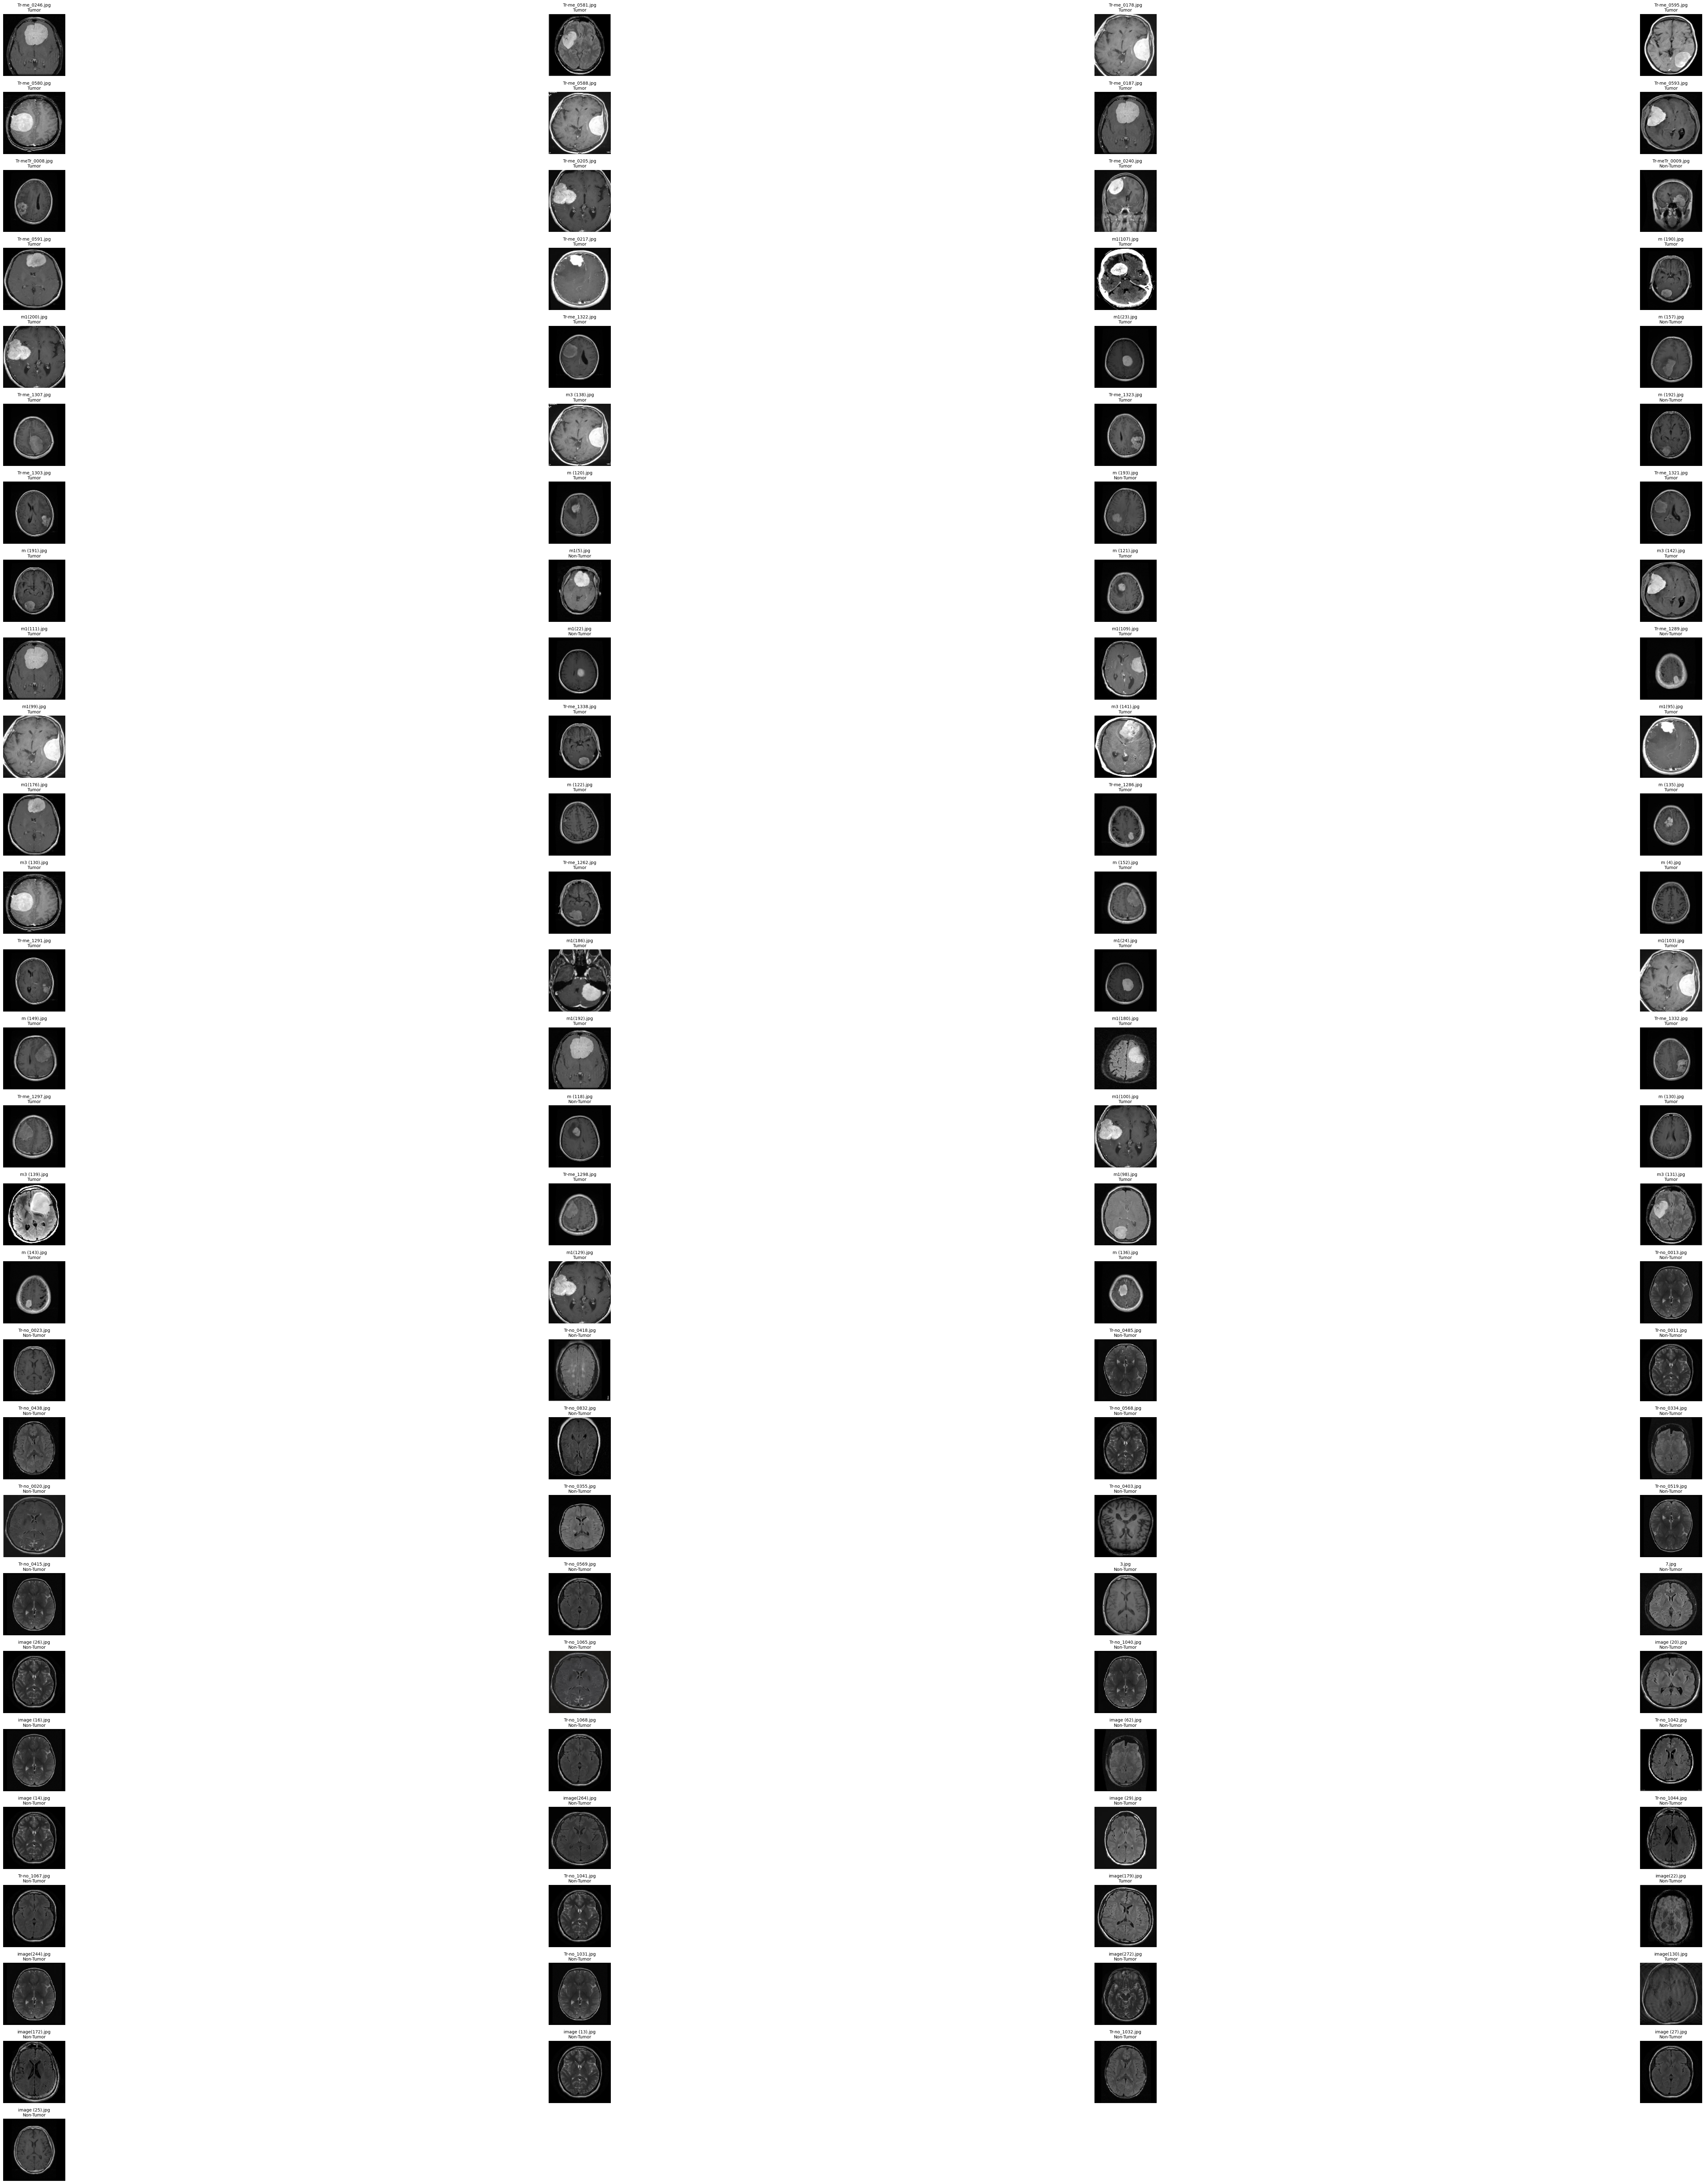

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.models import load_model

# Define the image size your model expects (adjust this as needed)
IMG_SIZE = (128, 128)

# Load the trained model
model = load_model('/content/drive/MyDrive/btd/brain_tumor_model.h5')  # Replace with your actual model file path

def predict_and_display_images(folder_path):
    # Collect all images and labels for display
    images = []
    labels = []
    filenames = []

    # Iterate over the images in the specified folder
    for file in os.listdir(folder_path):
        # Check if the file is an image
        if file.endswith(('.png', '.jpg', '.jpeg')):
            img_path = os.path.join(folder_path, file)
            # Load and resize the image
            img = load_img(img_path, target_size=IMG_SIZE)
            img_array = img_to_array(img) / 255.0  # Normalize the image
            img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

            # Make the prediction
            prediction = model.predict(img_array)
            label = "Tumor" if prediction[0][0] > 0.5 else "Non-Tumor"

            # Save the image and label for display
            images.append(img)
            labels.append(label)
            filenames.append(file)

    # Display the images with their labels
    plt.figure(figsize=(70, 70))
    for i in range(len(images)):
        plt.subplot(len(images) // 4 + 1, 4, i + 1)  # Adjust grid size for display
        plt.imshow(images[i])
        plt.title(f"{filenames[i]}\n{labels[i]}", fontsize=10)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

# Replace 'path_to_your_images_folder' with the actual folder path where your images are stored
predict_and_display_images('/content/drive/MyDrive/pred3')
